# LendingClub: прогноз дефолта по займу — проект по шагам

Итоговый проект по дисциплине **Programming for Data Analysis and Database**, тема №33.
Автор: Kilybayev Yersaiyn, AAI-2602M.

Этот ноутбук проходит весь проект в том же порядке, что и консольное меню `main.py`.
Он **не дублирует код**: каждая ячейка вызывает функции из папки `src/`, те же самые, что работают в меню и в дашборде.

**На каких данных он выполнен.** Сохранённые здесь результаты получены на **полном наборе: 2,26 млн займов**.
Ноутбук сам читает исходный файл Kaggle частями, строит базу, обучает и сравнивает модели; полный проход занимает
около 15 минут.

**Как запустить самому.**
- *С полными данными:* положите `accepted_2007_to_2018Q4.csv.gz` в папку `datasets/` (ссылка в README) и выполните все ячейки.
- *Без данных Kaggle:* ноутбук сам переключится на демо-выборку из репозитория (50 тыс. займов, 1–2 минуты).
  В выборке созревшие займы взяты с запасом, поэтому её числа отличаются от полного набора; пояснения в тексте
  относятся к полному запуску.

Всё, что создаёт ноутбук, пишется в отдельную папку (`notebook_run/` или `sample_run/`) и не меняет файлы в `reports/`.

In [1]:
# Только для Google Colab: снимите комментарии, чтобы скачать проект и установить библиотеки.
# !git clone https://github.com/yersaa/Loan_default_prediction.git
# %cd Loan_default_prediction
# !pip install -q -r requirements.txt

## 0. Настройка

`src/config.py` хранит все пути и списки колонок. Если есть полные данные, результаты ноутбука направляются
в `notebook_run/` (`redirect_outputs`); если нет — включается демо-выборка (`activate_sample`).

In [2]:
import warnings

import pandas as pd
from IPython.display import Image, display

from src import config as C
from src.data_io import csv_to_parquet, load_dataset, load_json, mb, memory_report

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="IProgress not found")  # SHAP ищет виджет прогресса, он здесь не нужен

FULL = C.RAW_CSV.exists() or C.PARQUET.exists()  # есть ли полные данные Kaggle
if FULL:
    C.redirect_outputs(C.NOTEBOOK_RUN)
else:
    C.activate_sample()
for folder in (C.REPORTS, C.FIGURES, C.MODELS):
    folder.mkdir(parents=True, exist_ok=True)


def show(name: str, width: int = 850) -> None:
    """Показывает график, построенный в этом запуске."""
    display(Image(filename=str(C.FIGURES / name), width=width))


print("Режим:", "полные данные" if FULL else "демо-выборка")
print("Результаты ноутбука:", C.REPORTS.relative_to(C.ROOT))

Режим: полные данные
Результаты ноутбука: notebook_run\reports


## 1. Данные: чтение частями, Parquet, оптимизация типов

Исходный файл Kaggle — `accepted_2007_to_2018Q4.csv.gz`: 2,26 млн строк, 151 колонка. Целиком в память он не помещается
(около 3 ГБ), поэтому `src/data_io.py`, функция `csv_to_parquet`:

1. читает CSV частями по 250 тыс. строк (`pd.read_csv(..., chunksize=...)`) и только нужные колонки;
2. чистит каждую часть (`clean_chunk`) и дописывает её в один файл Parquet;
3. заменяет прежний файл только после успешной записи всех частей.

In [3]:
if C.RAW_CSV.exists():
    ingest = csv_to_parquet()
else:
    print("Исходного CSV нет, используется готовый файл:", C.PARQUET.relative_to(C.ROOT))

  чанк 1: всего 250,000 строк


  чанк 2: всего 499,998 строк


  чанк 3: всего 749,992 строк


  чанк 4: всего 999,988 строк


  чанк 5: всего 1,249,986 строк


  чанк 6: всего 1,499,982 строк


  чанк 7: всего 1,749,977 строк


  чанк 8: всего 1,999,973 строк


  чанк 9: всего 2,249,969 строк
  чанк 10: всего 2,260,668 строк


Готово: {'rows_raw': 2260701, 'rows': 2260668, 'seconds': 28.7, 'csv_gz_mb': 374.4, 'parquet_mb': 123.1}


In [4]:
df = load_dataset()
print(f"Строк: {len(df):,}   колонок: {df.shape[1]}   в памяти: {mb(df)} МБ")
df.head(3)

Строк: 2,260,668   колонок: 49   в памяти: 385.9 МБ


,id,issue_d,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,acc_open_past_24mths,num_tl_op_past_12m,mo_sin_rcnt_tl,mo_sin_old_rev_tl_op,mo_sin_old_il_acct,mths_since_recent_bc,mths_since_recent_inq,mths_since_last_delinq,mths_since_last_record,total_bc_limit,bc_open_to_buy,bc_util,percent_bc_gt_75,total_rev_hi_lim,avg_cur_bal,total_bal_ex_mort,loan_status,total_pymnt,recoveries,last_pymnt_d
0,68407277,2015-12-01,3600.0,36 months,13.99,123.029999,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,debt_consolidation,PA,5.910000,0.0,2003-08-01,675.0,679.0,1.0,7.0,0.0,2765.0,29.700001,13.0,w,Individual,1.0,0.0,4.0,3.0,3.0,128.0,148.0,4.0,4.0,30.0,NaN,2400.0,1506.0,37.200001,0.0,9300.0,20701.0,7746.0,Fully Paid,4421.724121,0.0,2019-01-01
1,68355089,2015-12-01,24700.0,36 months,11.99,820.280029,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,small_business,SD,16.059999,1.0,1999-12-01,715.0,719.0,4.0,22.0,0.0,21470.0,19.200001,38.0,w,Individual,4.0,0.0,4.0,2.0,2.0,192.0,113.0,2.0,0.0,6.0,NaN,79300.0,57830.0,27.100000,7.7,111800.0,9733.0,39475.0,Fully Paid,25679.660156,0.0,2016-06-01
2,68341763,2015-12-01,20000.0,60 months,10.78,432.660004,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,home_improvement,IL,10.780000,0.0,2000-08-01,695.0,699.0,0.0,6.0,0.0,7869.0,56.200001,18.0,w,Joint App,5.0,0.0,6.0,0.0,14.0,184.0,125.0,101.0,10.0,NaN,NaN,6200.0,2737.0,55.900002,50.0,14000.0,31617.0,18696.0,Fully Paid,22705.923828,0.0,2017-06-01


**Оптимизация типов.** `optimize_dtypes` хранит строки с малым числом значений как `category`, а числа как `float32`.
Сравним 200 тыс. строк той же таблицы с обычными типами `object` и `float64`:

In [5]:
part = df.head(200_000)
plain = part.astype({c: "object" for c in C.CATEGORICAL} | {c: "float64" for c in C.FLOAT32})
print(f"Обычные типы: {mb(plain)} МБ   оптимизированные: {mb(part)} МБ   экономия в {mb(plain) / mb(part):.1f} раза")
del plain, part

Обычные типы: 191.6 МБ   оптимизированные: 34.1 МБ   экономия в 5.6 раза


`memory_report` делает то же сравнение с исходным файлом: все 151 колонка, только нужные, нужные с оптимизацией типов.
Оценка для полного набора получена пересчётом с 200 тыс. строк.

In [6]:
if C.RAW_CSV.exists():
    memory = memory_report()["full_dataset_estimate_mb"]
else:
    memory = load_json(C.ROOT / "reports" / "benchmarks.json")["memory"]["full_dataset_estimate_mb"]
sizes = {"все 151 колонка": memory["all_cols"], "только нужные колонки": memory["selected_cols"],
         "нужные колонки + category/float32": memory["selected_optimized"]}
pd.Series(sizes, name="память на полном наборе, МБ").to_frame()

,"память на полном наборе, МБ"
все 151 колонка,3084
только нужные колонки,1061
нужные колонки + category/float32,385


## 2. Аудит качества данных

`src/audit.py`, функция `run_audit`: пропуски, дубликаты, некорректные значения и выбросы по правилу 1,5·IQR.
По результатам аудита заданы правила очистки в `src/features.py`, `clean_values`.

In [7]:
from src.audit import run_audit

audit = run_audit(df)
print("Дубликатов id:", audit["duplicate_ids"])
pd.Series(audit["missing_pct"], name="пропуски, %").head(10).to_frame()

Дубликатов id: 0


,"пропуски, %"
mths_since_last_record,84.11
mths_since_last_delinq,51.25
mths_since_recent_inq,13.07
emp_length,6.50
mo_sin_old_il_acct,6.15
bc_util,3.36
percent_bc_gt_75,3.33
bc_open_to_buy,3.31
mths_since_recent_bc,3.25
avg_cur_bal,3.11


Больше всего пропусков у полей кредитного отчёта (`mths_since_last_record`, `mths_since_last_delinq`): пусто значит,
что события не было, либо что заём выдан до августа 2012 г., когда LendingClub ещё не публиковал эти поля.

In [8]:
pd.Series(audit["invalid_values"], name="строк с нарушением").to_frame()

,строк с нарушением
annual_inc <= 0,1667
dti < 0 или >= 999,137
revol_util > 150%,28
fico_range_low > fico_range_high,0
earliest_cr_line позже issue_d,0
int_rate вне 5–31%,0


**Проверка на утечку из будущего.** Поля кредитного отчёта должны относиться к моменту заявки. `bureau_timing` сравнивает
возраст самого старого счёта заёмщика с длиной его кредитной истории на дату выдачи. Если бы LendingClub обновлял
эти поля к дате выгрузки (2018 г.), у старых займов превышение составляло бы годы.

In [9]:
audit["bureau_timing"]

{'rows_checked': 2190391, 'max_excess_months': 10.0, 'rows_over_12_months': 0}

## 3. Целевая переменная, созревшие займы и разбиение по времени

`src/features.py`:

- `add_target`: `Fully Paid` → 0, `Charged Off` / `Default` → 1, остальные статусы — заём ещё не завершён;
- `is_matured`: срок займа истёк к декабрю 2018 г. Просто убрать статус `Current` нельзя: среди незрелых займов
  завершены только досрочно погашенные и уже списанные, и дефолтность по ним смещена;
- `build_features`: новые признаки из полей анкеты (`fico`, `credit_hist_months`, `loan_to_income` и др.);
- `temporal_split`: окна по году выдачи, без перемешивания.

In [10]:
from src.features import modeling_frame, temporal_split

model_df = modeling_frame(df.copy())
windows = temporal_split(model_df)
summary = {}
for name, window in windows.items():
    years = sorted(window["issue_d"].dt.year.unique())
    summary[name] = {"годы выдачи": str(years[0]) if len(years) == 1 else f"{years[0]}–{years[-1]}",
                     "займов": len(window), "дефолт, %": round(100 * float(window[C.TARGET].mean()), 2)}
pd.DataFrame(summary).T

,годы выдачи,займов,"дефолт, %"
fit,2007–2013,230706,15.65
valid,2014,162570,13.73
train,2007–2014,393276,14.85
test,2015,283026,14.89


`fit` и `valid` — части `train`. На `fit` подбираются гиперпараметры, на `valid` — калибровка, порог и выбор модели.
`test` используется один раз, для итоговой оценки.

**Признаки.** В модель идут только поля, известные до выдачи займа. Пересечение списка признаков со списком полей,
которые появляются после выдачи, должно быть пустым:

In [11]:
print("Признаков:", len(C.FEATURES), "— из них полей кредитного отчёта:", len(C.BUREAU_COLS))
print("Пересечение с полями после выдачи:", set(C.FEATURES) & set(C.LEAKAGE_COLS) or "пусто")
print("Назначает LendingClub, а не заёмщик:", sorted(C.LC_ASSIGNED))

Признаков: 43 — из них полей кредитного отчёта: 16
Пересечение с полями после выдачи: пусто
Назначает LendingClub, а не заёмщик: ['grade', 'initial_list_status', 'installment', 'installment_to_income', 'int_rate', 'sub_grade', 'verification_status']


## 4. База данных SQLite и SQL-запросы

`src/database.py`, функция `build_database`, раскладывает плоскую таблицу по нормализованной схеме из `sql/schema.sql`:
четыре справочника и три таблицы — `loans` (условия займа), `borrowers` (профиль заёмщика), `outcomes` (исход).

![ER-диаграмма](docs/er_diagram.png)

In [12]:
from src.database import build_database, load_queries, run_all_queries

build_database(df.copy())

  dim_grade             35 строк
  dim_purpose           14 строк
  dim_state             51 строк
  dim_home               6 строк


  loans          2,260,668 строк


  borrowers      2,260,668 строк


  outcomes       2,260,668 строк


{'dim_grade': 35,
 'dim_purpose': 14,
 'dim_state': 51,
 'dim_home': 6,
 'loans': 2260668,
 'borrowers': 2260668,
 'outcomes': 2260668,
 'seconds': 70.7,
 'db_mb': 613.2}

Запросы лежат в `sql/queries.sql`. `load_queries` читает файл в словарь `{имя: текст SQL}`,
`run_query` выполняет запрос и возвращает результат в Pandas. Пример запроса с CTE и оконной функцией:

In [13]:
queries = load_queries()
print(len(queries), "запросов:", ", ".join(queries))
print()
print(queries["state_rank"])

10 запросов: default_by_grade, purpose_having, vintage_by_year_term, state_rank, monthly_rolling, yoy_volume_lag, dti_deciles, income_vs_grade_avg, loss_by_grade, fico_home_matrix

-- 4. CTE + оконные RANK(): рейтинг штатов по дефолтности в целом и внутри региона
WITH state_stats AS (
    SELECT s.state_code, s.region,
           COUNT(*)                          AS loans,
           ROUND(AVG(o.is_default) * 100, 2) AS default_rate_pct
    FROM loans l
    JOIN outcomes o  ON o.loan_id = l.loan_id
    JOIN dim_state s ON s.state_code = l.state_code
    WHERE o.is_default IS NOT NULL AND o.is_matured = 1
    GROUP BY s.state_code, s.region
    HAVING COUNT(*) >= 1000
)
SELECT *,
       RANK() OVER (ORDER BY default_rate_pct DESC)                     AS rank_overall,
       RANK() OVER (PARTITION BY region ORDER BY default_rate_pct DESC) AS rank_in_region
FROM state_stats
ORDER BY rank_overall;


In [14]:
results = run_all_queries()

  default_by_grade            7 строк   0.97 c


  purpose_having              8 строк   0.86 c


  vintage_by_year_term       21 строк   3.19 c


  state_rank                 46 строк   1.14 c


  monthly_rolling           103 строк   1.18 c


  yoy_volume_lag             48 строк   3.63 c


  dti_deciles                10 строк   1.86 c


  income_vs_grade_avg        14 строк  14.85 c


  loss_by_grade               7 строк   0.42 c


  fico_home_matrix           12 строк   1.53 c


In [15]:
results["state_rank"].head(8)

,state_code,region,loans,default_rate_pct,rank_overall,rank_in_region
0,MS,South,2501,18.79,1,1
1,NV,West,9899,18.08,2,1
2,AR,South,4962,17.82,3,2
3,OK,South,5989,17.57,4,3
4,AL,South,8131,17.34,5,4
5,TN,South,9084,16.80,6,5
6,LA,South,7879,16.61,7,6
7,FL,South,47487,16.42,8,7


Дефолтность и средняя ставка по грейдам (JOIN + GROUP BY). Дефолтность растёт от A к G вместе со ставкой:

In [16]:
results["default_by_grade"]

,grade,loans,default_rate_pct,avg_int_rate
0,A,144214,5.50,7.23
1,B,220196,11.38,10.90
2,C,180210,18.31,14.08
3,D,87126,23.84,17.29
4,E,32147,29.41,20.12
5,F,10349,34.52,23.25
6,G,2060,37.43,24.30


Доход относительно среднего по своему подгрейду (CTE + подзапрос). Внутри одного грейда заёмщики с доходом ниже
среднего дефолтят чаще: грейд учитывает доход не полностью.

In [17]:
results["income_vs_grade_avg"].pivot(index="grade", columns="income_group", values="default_rate_pct")

income_group,above_avg,below_avg
grade,,
A,4.49,6.12
B,9.88,12.26
C,15.90,19.72
D,21.44,25.24
E,26.76,30.98
F,30.82,36.89
G,33.82,39.54


## 5. EDA и графики

`src/eda.py`, функция `run_eda`, строит шесть статических графиков и два интерактивных. Часть графиков берёт данные
прямо из SQL-запросов.

In [18]:
from src.eda import run_eda

created = run_eda(df, model_df)
print(len(created), "файлов в", C.FIGURES.relative_to(C.ROOT))

14 файлов в notebook_run\reports\figures


Грейды LendingClub отражают риск: чем хуже грейд, тем выше и дефолтность, и ставка.

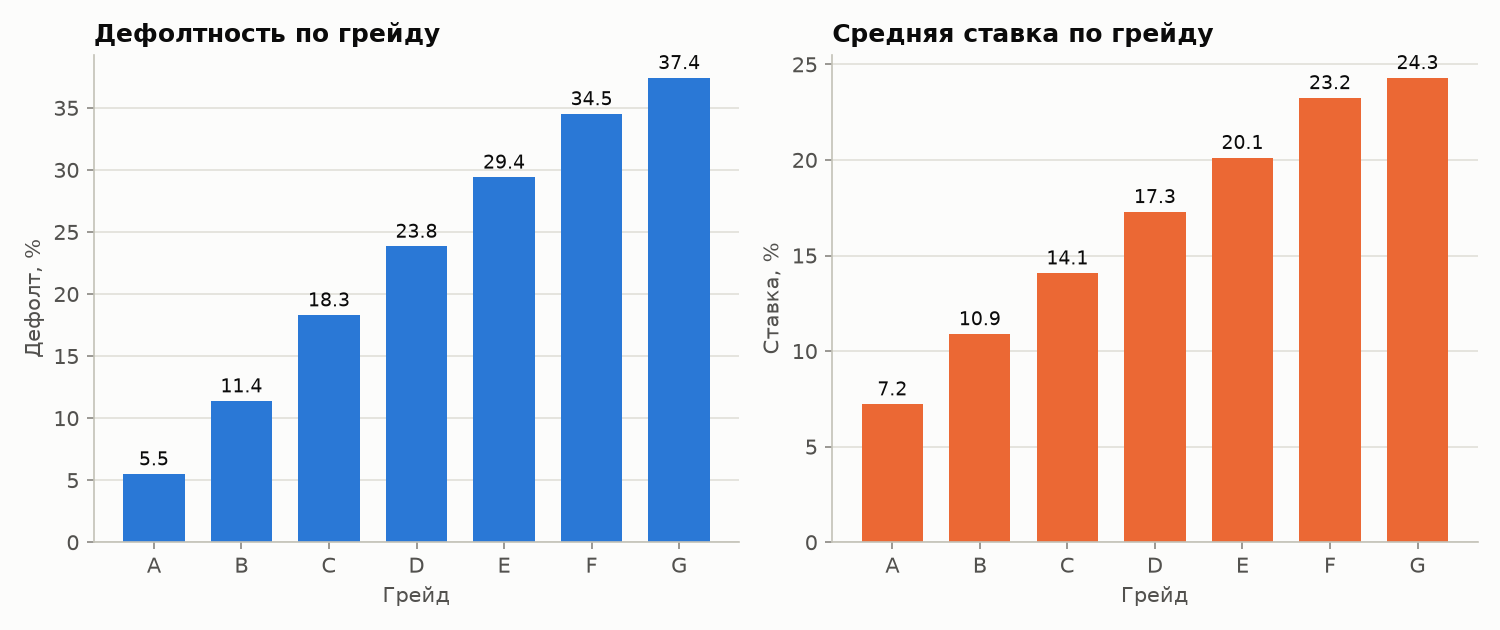

In [19]:
show("02_default_by_grade.png")

Цензурирование: чем моложе займы, тем меньшая их доля завершена и тем выше дефолтность среди завершённых.
Поэтому в модель идут только созревшие займы.

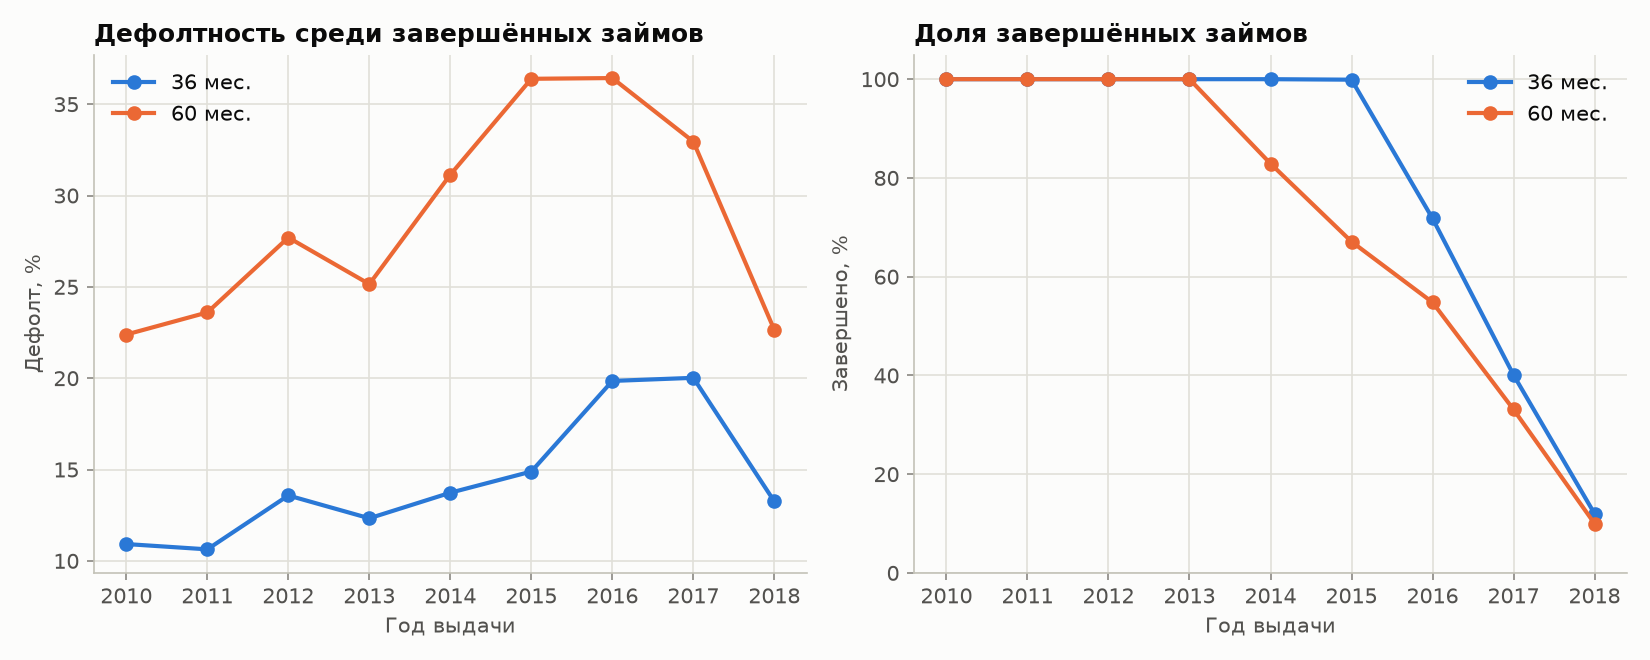

In [20]:
show("03_vintage.png")

## 6. Модели: подбор, обучение, сравнение

`src/models.py`. Сравниваются шесть моделей (`model_specs`):

| Модель | Роль |
|---|---|
| Dummy | baseline: константа, равная доле дефолтов |
| Только подгрейд LC | baseline: оценка самого LendingClub |
| Logistic Regression, LightGBM | все поля, известные до выдачи |
| Те же две модели | только поля заёмщика, без оценок LendingClub (грейд, ставка) |

Сначала `tune` подбирает гиперпараметры на окне `fit` с разбиением по времени (`TimeSeriesSplit`).

In [21]:
from src.data_io import save_json
from src.models import train_and_compare, tune

fit = windows["fit"]
best = tune(fit[C.FEATURES], fit[C.TARGET].astype(int))
save_json(best, C.REPORTS / "tuning.json")  # подобранные значения нужны и для замера памяти моделей в разделе 10

  Logistic Regression: {'model__C': 0.05}  CV ROC-AUC=0.6904


  LightGBM: {'model__n_estimators': 300, 'model__num_leaves': 15}  CV ROC-AUC=0.6948


  Logistic Regression (borrower only): {'model__C': 1.0}  CV ROC-AUC=0.6850


  LightGBM (borrower only): {'model__n_estimators': 300, 'model__num_leaves': 15}  CV ROC-AUC=0.6936


`train_and_compare` для каждой модели вызывает `fit_one`:

1. пробная модель учится на `fit` и делает прогноз на `valid`; по нему подбираются калибровка Платта и порог;
2. финальная модель учится на `train` и оценивается на `test`.

In [22]:
metrics, fitted, preds, preds_raw, test = train_and_compare(model_df, best)
metrics[["model", "valid_auc", "roc_auc", "gini", "ks", "pr_auc", "brier", "ece", "f1"]]

  Dummy (prior)                        ROC-AUC=0.5000  KS=0.000  fit=0.0c


  Grade only (LogReg)                  ROC-AUC=0.6786  KS=0.262  fit=0.5c


  Logistic Regression                  ROC-AUC=0.6950  KS=0.284  fit=6.4c


  LightGBM                             ROC-AUC=0.7034  KS=0.295  fit=6.4c


  Logistic Regression (borrower only)  ROC-AUC=0.6781  KS=0.258  fit=4.0c


  LightGBM (borrower only)             ROC-AUC=0.6927  KS=0.279  fit=5.4c


,model,valid_auc,roc_auc,gini,ks,pr_auc,brier,ece,f1
0,Dummy (prior),0.5000,0.5000,0.0000,0.0000,0.1489,0.1267,0.0003,0.2591
1,Grade only (LogReg),0.6595,0.6786,0.3573,0.2619,0.2505,0.1209,0.0202,0.3353
2,Logistic Regression,0.6804,0.6950,0.3901,0.2838,0.2708,0.1191,0.0106,0.3492
3,LightGBM,0.6888,0.7034,0.4068,0.2952,0.2833,0.1182,0.0093,0.3554
4,Logistic Regression (borrower only),0.6684,0.6781,0.3561,0.2581,0.2577,0.1204,0.0102,0.3361
5,LightGBM (borrower only),0.6809,0.6927,0.3855,0.2794,0.2724,0.1191,0.0085,0.3455


**Правило выбора модели** задано заранее в `config.SIMPLICITY_MARGIN_AUC` и применяется к валидации, а не к тесту:
берётся лучшая ROC-AUC на 2014 годе, но логистическая регрессия предпочитается, если отстаёт меньше чем на 0,005.

In [23]:
selection = load_json(C.REPORTS / "model_selection.json")
selection

{'rule': 'max valid_auc (2014); логрегрессия, если отстаёт меньше чем на 0.005',
 'best_by_valid_auc': 'LightGBM',
 'selected': 'LightGBM',
 'valid_auc': {'Logistic Regression': 0.6804,
  'LightGBM': 0.6888,
  'Logistic Regression (borrower only)': 0.6684,
  'LightGBM (borrower only)': 0.6809}}

## 7. Интерпретация и анализ ошибок

`src/explain.py`, функция `run_explain`: ROC и PR, матрица ошибок, калибровка, SHAP, ошибки по грейдам, таблица одобрения.
Таблица ниже показывает качество LightGBM внутри каждого грейда.

In [24]:
from src.explain import run_explain

explained = run_explain(fitted, preds, preds_raw, test, metrics)
explained["errors"]

,grade,loans,actual_default_pct,predicted_pd_pct,auc_within_grade,missed_defaults_pct,false_alarms_pct
0,A,70118,5.42,5.27,0.65,99.26,0.19
1,B,91725,11.90,11.31,0.62,77.71,12.29
2,C,77423,19.44,18.54,0.61,26.30,59.54
3,D,32711,26.22,24.03,0.60,6.73,85.83
4,E,9443,32.84,29.57,0.60,1.42,96.78
5,F,1361,42.40,34.61,0.61,0.35,97.70
6,G,245,46.12,38.62,0.62,0.00,100.00


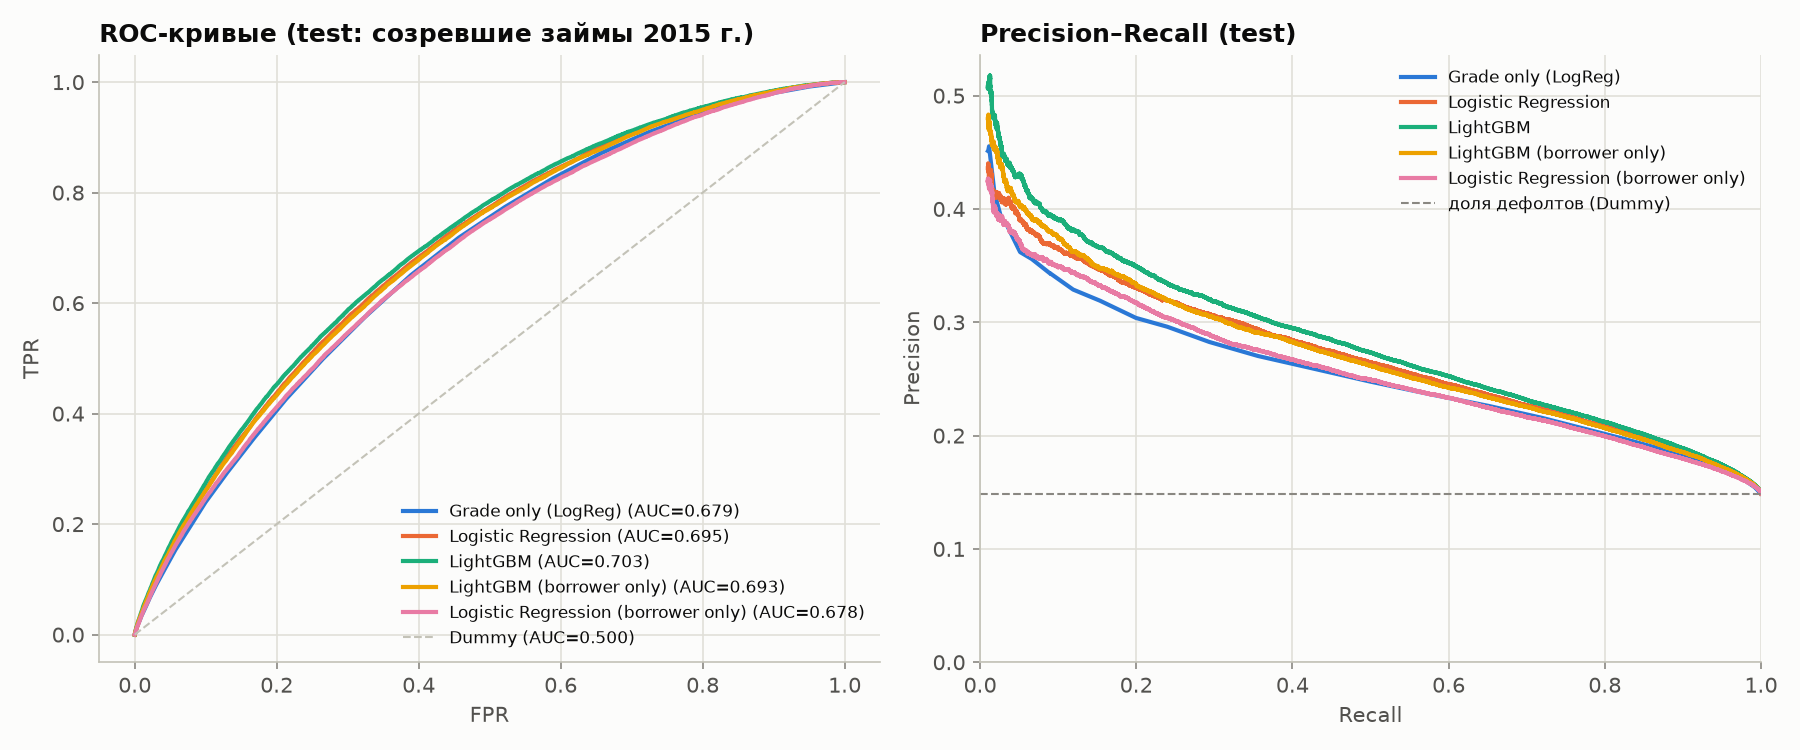

In [25]:
show("09_roc_pr.png")

SHAP для LightGBM на всех полях: какие признаки сильнее всего сдвигают прогноз.

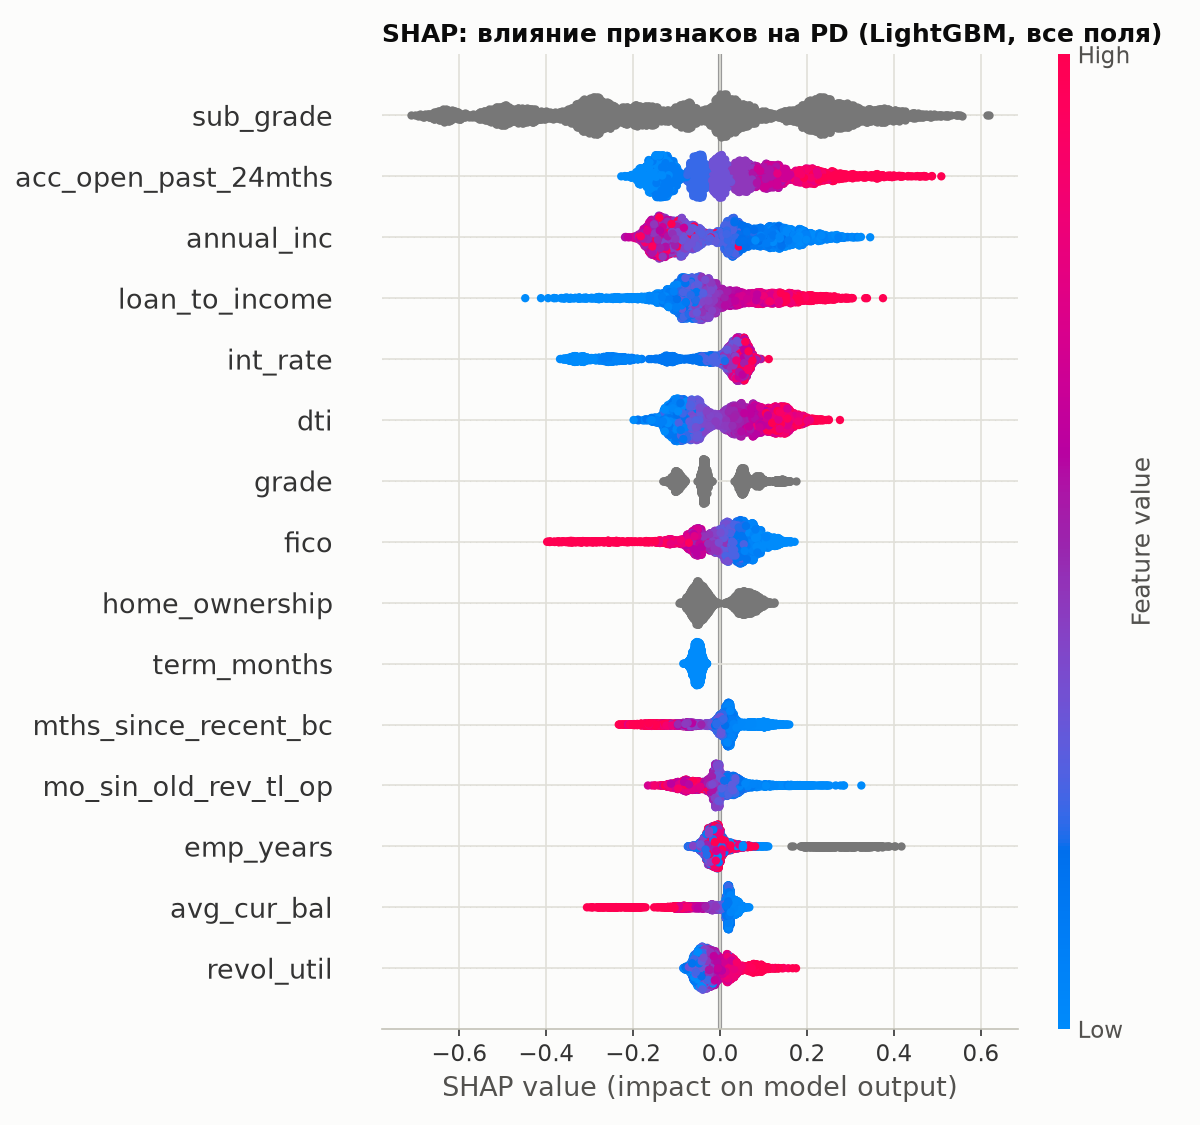

In [26]:
show("12_shap_summary.png", width=650)

**Что добавляет грейд LendingClub.** Сравнение модели только на данных заёмщика с одним подгрейдом и с моделью
на всех полях (ROC-AUC на тесте):

In [27]:
auc = metrics.set_index("model")["roc_auc"]
pd.Series({"только подгрейд LendingClub": auc["Grade only (LogReg)"],
           "LightGBM, только поля заёмщика": auc["LightGBM (borrower only)"],
           "LightGBM, все поля": auc["LightGBM"]}, name="ROC-AUC на тесте").to_frame()

,ROC-AUC на тесте
только подгрейд LendingClub,0.6786
"LightGBM, только поля заёмщика",0.6927
"LightGBM, все поля",0.7034


**Таблица одобрения.** Если одобрять не все заявки, а долю с наименьшей вероятностью дефолта, дефолтность портфеля
снижается. Это практическая польза модели. В таблице — дефолтность одобренного портфеля, %.

In [28]:
explained["approval"].pivot(index="approval_rate", columns="model", values="default_rate_pct").round(1)

model,Grade only (LogReg),LightGBM,LightGBM (borrower only),Logistic Regression
approval_rate,,,,
0.5,8.2,7.5,7.9,7.8
0.6,9.4,8.7,9.0,8.9
0.7,10.6,9.9,10.2,10.1
0.8,11.9,11.2,11.5,11.4
0.9,13.2,12.8,12.9,12.9
1.0,14.9,14.9,14.9,14.9


## 8. Проверка: насколько цензурирование завышает результат

`src/censoring.py` обучает те же модели на «всех завершённых» займах, включая незрелые 60-месячные.
Общая AUC на такой когорте выше, но внутри 36-месячных займов (`auc_36m`) она почти та же:
завышение создаётся смешением сроков, а не качеством модели.

In [29]:
from src.censoring import censoring_sensitivity

censoring_sensitivity(df, best)

,cohort,model,train_rows,test_rows,train_default_pct,test_default_pct,mean_pd_pct,test_auc,auc_36m,auc_60m
0,созревшие (основной),Logistic Regression,393276,283026,14.85,14.89,13.35,0.6950,0.6950,NaN
1,созревшие (основной),LightGBM,393276,283026,14.85,14.89,13.17,0.7034,0.7034,NaN
2,все завершённые (смещённый),Logistic Regression,453809,375546,17.03,20.19,17.83,0.7345,0.6955,0.6757
3,все завершённые (смещённый),LightGBM,453809,375546,17.03,20.19,17.57,0.7399,0.7036,0.6793


## 9. Оценка одной заявки

`predict_pd` проверяет анкету (`validate_application`), собирает строку признаков тем же кодом, что при обучении,
и возвращает калиброванную вероятность дефолта от каждой модели. Поля, которых нет в анкете (например, данные
кредитного отчёта), заполняются типичными значениями из обучающих данных.

In [30]:
from src.models import predict_pd

application = {
    "loan_amnt": 15000, "term_months": 36, "int_rate": 13.0, "sub_grade": "C1", "annual_inc": 65000, "dti": 18,
    "fico": 700, "emp_years": 5, "revol_util": 50, "inq_last_6mths": 1, "credit_hist_months": 180,
    "home_ownership": "RENT", "purpose": "debt_consolidation", "verification_status": "Source Verified",
    "initial_list_status": "w", "application_type": "Individual",
}
pd.DataFrame(predict_pd(application)).T

,pd,threshold,decision
LightGBM,0.135456,0.16,одобрить
Logistic Regression,0.160698,0.16,отказ
LightGBM (borrower only),0.099524,0.16,одобрить


Некорректная анкета отклоняется с понятным сообщением (обработка ошибок через `try` / `except`):

In [31]:
try:
    predict_pd({**application, "fico": 300})
except ValueError as error:
    print("Ошибка:", error)

Ошибка: fico = 300: допустимо от 600 до 850


## 10. Сравнение способов обработки данных

`src/benchmark.py`: каждая задача выполняется в отдельном новом процессе три раза, в отчёт идёт медиана.
Сравниваются чтение CSV и Parquet, агрегация в Pandas и в SQLite, а также память обучения каждой модели.
Без исходного CSV показывается результат полного запуска из репозитория.

In [32]:
if C.RAW_CSV.exists():
    from src.benchmark import run_benchmarks
    bench = run_benchmarks()
else:
    bench = load_json(C.ROOT / "reports" / "benchmarks.json")

  Dummy (prior)                        память обучения    10.5 МБ


  Grade only (LogReg)                  память обучения    40.8 МБ


  Logistic Regression                  память обучения   663.9 МБ


  LightGBM                             память обучения   233.5 МБ


  Logistic Regression (borrower only)  память обучения   338.9 МБ


  LightGBM (borrower only)             память обучения   206.1 МБ


In [33]:
rows = {
    "чтение 6 колонок: CSV.gz": bench["csv_vs_parquet"]["csv_gz"],
    "чтение 6 колонок: Parquet": bench["csv_vs_parquet"]["parquet"],
    "агрегация: Pandas + Parquet": bench["pandas_vs_sql"]["pandas_parquet"],
    "агрегация: SQLite": bench["pandas_vs_sql"]["sqlite"],
}
print("Результаты Pandas и SQL совпали:", bench["pandas_vs_sql"]["results_match"])
pd.DataFrame(rows).T[["seconds", "peak_mb"]].rename(columns={"seconds": "время, с", "peak_mb": "пик памяти, МБ"})

Результаты Pandas и SQL совпали: True


,"время, с","пик памяти, МБ"
чтение 6 колонок: CSV.gz,9.35,161.8
чтение 6 колонок: Parquet,0.21,222.4
агрегация: Pandas + Parquet,0.82,390.5
агрегация: SQLite,2.5,5.3


Время и память моделей: качество — не единственный критерий выбора.

In [34]:
cost = metrics[["model", "fit_seconds", "predict_ms_per_1000", "model_mb"]].copy()
cost.insert(2, "fit_peak_mb", cost["model"].map(lambda name: bench["model_fit_memory"][name]["fit_peak_mb"]))
cost

,model,fit_seconds,fit_peak_mb,predict_ms_per_1000,model_mb
0,Dummy (prior),0.0313,10.5,0.0525,0.0015
1,Grade only (LogReg),0.5320,40.8,0.3474,0.0042
2,Logistic Regression,6.4345,663.9,2.6980,0.0101
3,LightGBM,6.3730,233.5,6.4785,0.5260
4,Logistic Regression (borrower only),4.0364,338.9,1.6608,0.0085
5,LightGBM (borrower only),5.3651,206.1,6.2378,0.5248


## Итог

In [35]:
auc = metrics.set_index("model")
chosen = selection["selected"]
print(f"Выбрана модель: {chosen}")
best_row = auc.loc[chosen]
print(f"  ROC-AUC на тесте {best_row['roc_auc']:.3f}, Gini {best_row['gini']:.3f}, KS {best_row['ks']:.3f}")
print(f"  baseline «только подгрейд»: {auc.loc['Grade only (LogReg)', 'roc_auc']:.3f}, Dummy: 0.500")
print(f"  средняя PD {100 * auc.loc[chosen, 'mean_pd']:.1f}% при фактической дефолтности "
      f"{100 * auc.loc[chosen, 'actual_default_rate']:.1f}%")

Выбрана модель: LightGBM
  ROC-AUC на тесте 0.703, Gini 0.407, KS 0.295
  baseline «только подгрейд»: 0.679, Dummy: 0.500
  средняя PD 14.0% при фактической дефолтности 14.9%


- Parquet и оптимизация типов позволяют работать с 2,26 млн займов на обычном компьютере.
- Незавершённые 60-месячные займы завышают оценку качества, поэтому в модель идут только созревшие займы.
- Модель выбирается по заранее заданному правилу на валидации, а тест используется один раз.
- Поля кредитного отчёта заметно усиливают модель на данных заёмщика; оценки LendingClub (грейд и ставка) добавляют к ней немного.

Полное описание методов, ограничений и выводов — в `docs/report.pdf`. Интерактивная версия аналитики и скоринга:
`streamlit run app.py`.